In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor
import warnings
warnings.filterwarnings('ignore')

In [2]:
data=pd.read_csv(r"C:\Users\tech\Downloads\synthetic_ev_battery_5year_50cols_multimfg_3M.csv")
data

,cell_id,manufacturer,chemistry_type,nominal_capacity_Ah,nominal_voltage_V,energy_density_Wh_per_kg,energy_density_Wh_per_L,manufacture_year,timestamp,cycle_number,...,min_voltage_limit_V,min_temp_limit_C,safety_margin_index,overcurrent_flag,undercurrent_flag,over_voltage_flag,under_voltage_flag,over_temperature_flag,under_temperature_flag,short_circuit_flag
0,CELL_001,GreenLithium Tech,NMC,3.2,3.7,250,600,2020,2021-01-01 00:00:00,0,...,2.5,-20,0.659063,0,0,0,0,0,0,0
1,CELL_001,FutureCharge Inc,LFP,3.2,3.7,250,600,2020,2021-01-01 00:00:52,0,...,2.5,-20,0.990124,0,0,0,0,0,0,0
2,CELL_001,PowerNova Systems,NCA,3.2,3.7,250,600,2020,2021-01-01 00:01:44,0,...,2.5,-20,0.924636,0,0,0,0,0,0,0
3,CELL_001,FutureCharge Inc,LFP,3.2,3.7,250,600,2020,2021-01-01 00:02:36,0,...,2.5,-20,0.941941,0,0,0,0,0,0,0
4,CELL_001,FutureCharge Inc,LFP,3.2,3.7,250,600,2020,2021-01-01 00:03:28,0,...,2.5,-20,0.895553,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2999995,CELL_001,FutureCharge Inc,LFP,3.2,3.7,250,600,2020,2025-12-11 13:15:40,999,...,2.5,-20,0.928338,0,0,0,0,0,0,0
2999996,CELL_001,GreenLithium Tech,NMC,3.2,3.7,250,600,2020,2025-12-11 13:16:32,999,...,2.5,-20,0.503063,0,0,0,0,0,0,0
2999997,CELL_001,PowerNova Systems,NCA,3.2,3.7,250,600,2020,2025-12-11 13:17:24,999,...,2.5,-20,0.931142,0,0,0,0,0,0,0
2999998,CELL_001,VoltCore Energy,NMC,3.2,3.7,250,600,2020,2025-12-11 13:18:16,999,...,2.5,-20,0.062781,0,0,0,0,0,0,0


In [3]:
selected_columns = [
    'manufacturer',
    'chemistry_type',
    'nominal_capacity_Ah',
    'nominal_voltage_V',
    'cycle_number',
    'voltage_V',
    'current_A',
    'c_rate',
    'state_of_charge_%',
    'depth_of_discharge_%',
    'cell_temperature_C',
    'internal_resistance_mOhm',
    'state_of_health_%'
]
data = data[selected_columns]
data = data.sample(n=25000, random_state=42)

In [4]:
print(data.shape)

(25000, 13)


In [5]:
data.head()

,manufacturer,chemistry_type,nominal_capacity_Ah,nominal_voltage_V,cycle_number,voltage_V,current_A,c_rate,state_of_charge_%,depth_of_discharge_%,cell_temperature_C,internal_resistance_mOhm,state_of_health_%
2945667,VoltCore Energy,NMC,3.2,3.7,981,3.603253,2.017816,0.630567,50.041208,49.958792,23.889830,57.322687,87.225499
2352586,FutureCharge Inc,LFP,3.2,3.7,784,3.609348,-1.249170,-0.390366,50.033269,49.966731,25.300146,45.881828,93.719021
1531260,VoltCore Energy,NMC,3.2,3.7,510,3.606734,2.006436,0.627011,50.101706,49.898294,24.682658,53.559994,93.353260
941910,GreenLithium Tech,NMC,3.2,3.7,313,3.589238,-1.398775,-0.437117,49.896473,50.103527,24.908062,54.483301,95.442088
2582125,VoltCore Energy,NMC,3.2,3.7,860,3.587664,0.132897,0.041530,49.953602,50.046398,25.735472,56.298644,88.812086


In [6]:
data.tail()

,manufacturer,chemistry_type,nominal_capacity_Ah,nominal_voltage_V,cycle_number,voltage_V,current_A,c_rate,state_of_charge_%,depth_of_discharge_%,cell_temperature_C,internal_resistance_mOhm,state_of_health_%
1985778,VoltCore Energy,NMC,3.2,3.7,661,3.609125,2.504181,0.782557,49.902623,50.097377,25.736001,54.715317,91.382089
682131,VoltCore Energy,NMC,3.2,3.7,227,3.623164,1.311426,0.409821,50.069603,49.930397,23.452635,51.526719,97.037034
121447,FutureCharge Inc,LFP,3.2,3.7,40,3.626138,-2.170852,-0.678391,50.147088,49.852912,24.395424,43.145167,99.663538
1430932,VoltCore Energy,NMC,3.2,3.7,476,3.607667,1.579792,0.493685,50.092691,49.907309,26.970825,53.309250,93.792353
1619200,FutureCharge Inc,LFP,3.2,3.7,539,3.597733,-4.733215,-1.479130,49.896089,50.103911,24.435873,44.953679,95.654017


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 2945667 to 1619200
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   manufacturer              25000 non-null  object 
 1   chemistry_type            25000 non-null  object 
 2   nominal_capacity_Ah       25000 non-null  float64
 3   nominal_voltage_V         25000 non-null  float64
 4   cycle_number              25000 non-null  int64  
 5   voltage_V                 25000 non-null  float64
 6   current_A                 25000 non-null  float64
 7   c_rate                    25000 non-null  float64
 8   state_of_charge_%         25000 non-null  float64
 9   depth_of_discharge_%      25000 non-null  float64
 10  cell_temperature_C        25000 non-null  float64
 11  internal_resistance_mOhm  25000 non-null  float64
 12  state_of_health_%         25000 non-null  float64
dtypes: float64(10), int64(1), object(2)
memory usage: 2.7+ MB


In [8]:
data.describe()

,nominal_capacity_Ah,nominal_voltage_V,cycle_number,voltage_V,current_A,c_rate,state_of_charge_%,depth_of_discharge_%,cell_temperature_C,internal_resistance_mOhm,state_of_health_%
count,2.500000e+04,2.500000e+04,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,3.200000e+00,3.700000e+00,498.219320,3.599643,0.023055,0.007205,49.992122,50.007878,25.062413,52.400763,93.848136
std,4.440981e-16,8.881962e-16,288.426808,0.019958,2.493764,0.779301,0.106132,0.106132,0.993829,6.059519,4.003439
min,3.200000e+00,3.700000e+00,0.000000,3.511491,-10.316262,-3.223832,49.631365,49.453057,21.278979,43.002369,83.491321
25%,3.200000e+00,3.700000e+00,250.000000,3.586197,-1.687838,-0.527449,49.925584,49.955005,24.383718,46.431410,91.167421
50%,3.200000e+00,3.700000e+00,497.000000,3.599525,0.033081,0.010338,49.991205,50.008795,25.058788,52.758757,94.321836
75%,3.200000e+00,3.700000e+00,750.000000,3.613142,1.705077,0.532836,50.044995,50.074416,25.746030,56.926433,97.152123
max,3.200000e+00,3.700000e+00,999.000000,3.677500,10.195560,3.186112,50.546943,50.368635,29.102838,65.875111,99.994491


In [9]:
data.dtypes

manufacturer                 object
chemistry_type               object
nominal_capacity_Ah         float64
nominal_voltage_V           float64
cycle_number                  int64
voltage_V                   float64
current_A                   float64
c_rate                      float64
state_of_charge_%           float64
depth_of_discharge_%        float64
cell_temperature_C          float64
internal_resistance_mOhm    float64
state_of_health_%           float64
dtype: object

In [10]:
data.isna().sum()

manufacturer                0
chemistry_type              0
nominal_capacity_Ah         0
nominal_voltage_V           0
cycle_number                0
voltage_V                   0
current_A                   0
c_rate                      0
state_of_charge_%           0
depth_of_discharge_%        0
cell_temperature_C          0
internal_resistance_mOhm    0
state_of_health_%           0
dtype: int64

In [11]:
data.duplicated().any()

np.False_

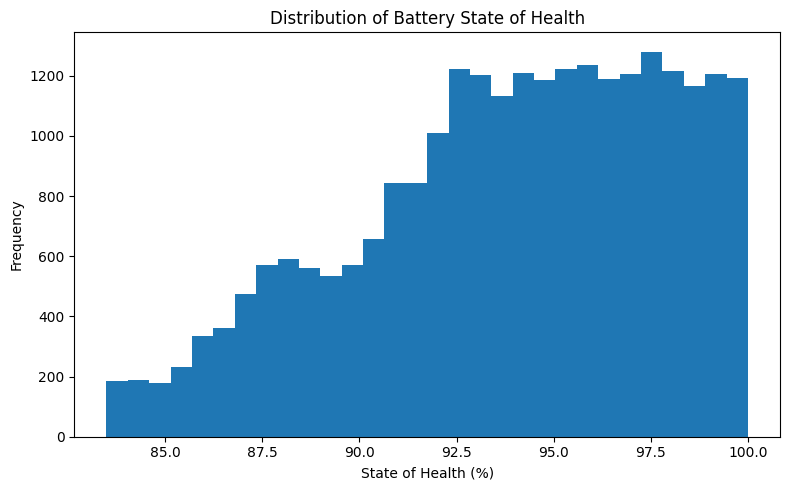

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(data['state_of_health_%'], bins=30)
plt.title('Distribution of Battery State of Health')
plt.xlabel('State of Health (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

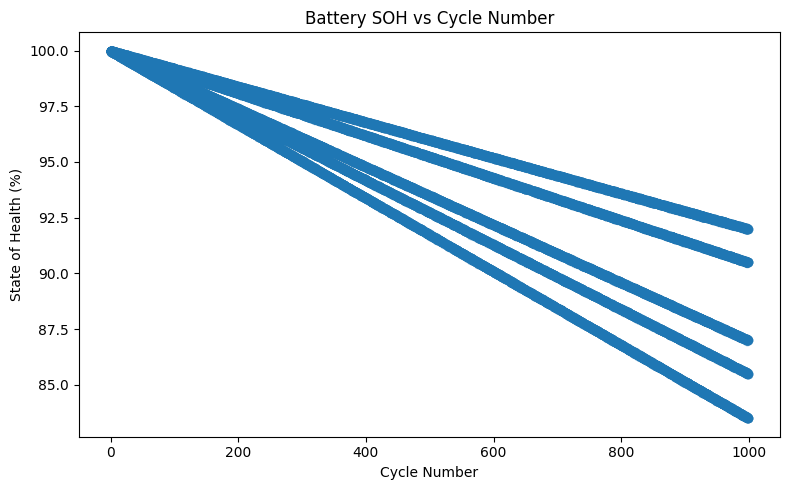

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(data['cycle_number'],data['state_of_health_%'],alpha=0.4)
plt.title('Battery SOH vs Cycle Number')
plt.xlabel('Cycle Number')
plt.ylabel('State of Health (%)')
plt.tight_layout()
plt.show()

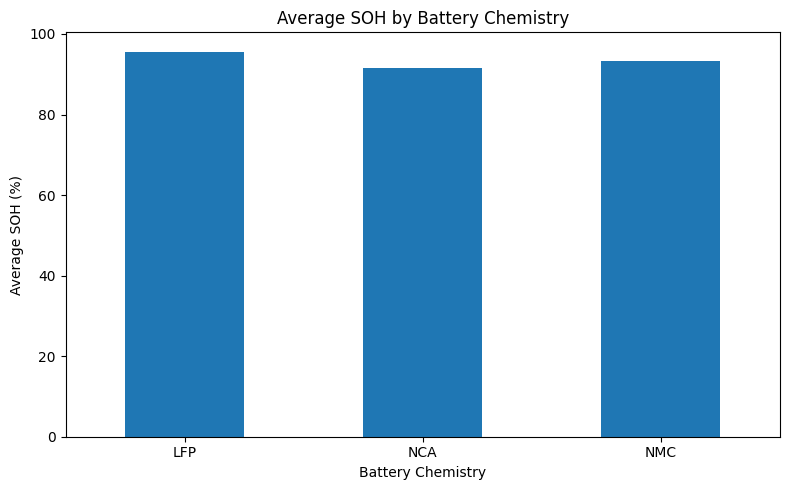

In [14]:
plt.figure(figsize=(8, 5))
data.groupby('chemistry_type')['state_of_health_%'].mean().plot(kind='bar')
plt.title('Average SOH by Battery Chemistry')
plt.xlabel('Battery Chemistry')
plt.ylabel('Average SOH (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

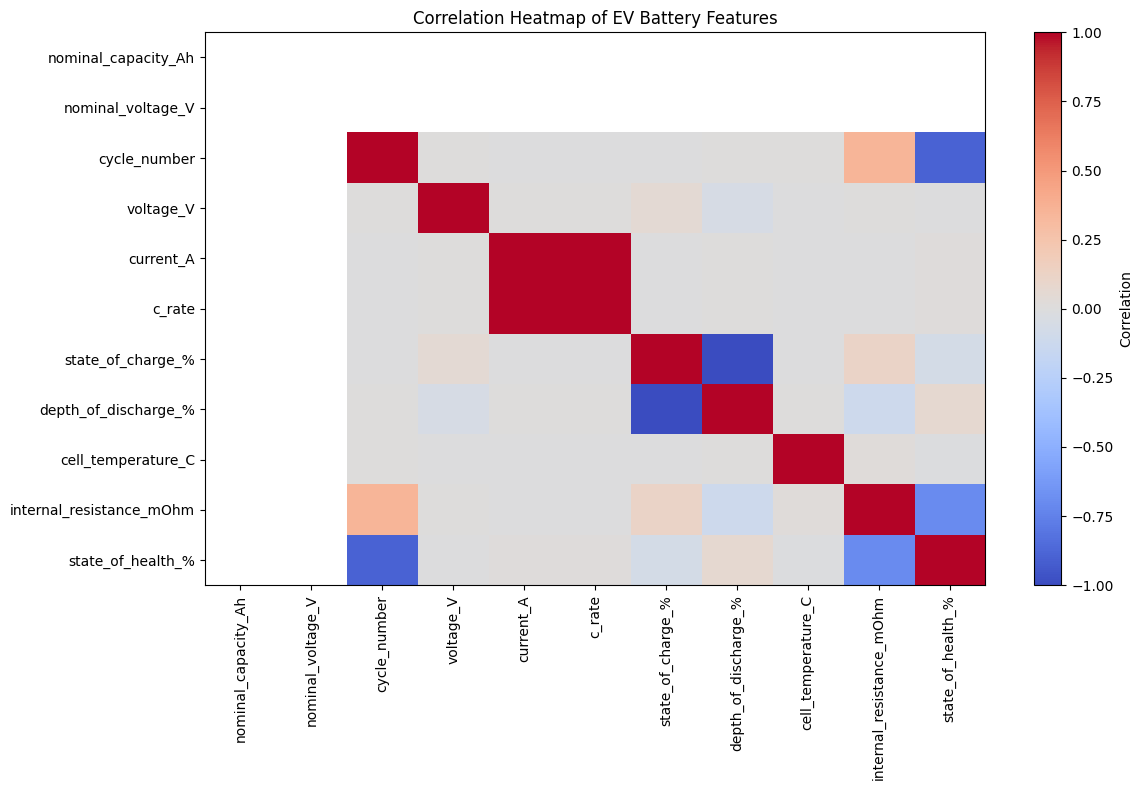

In [15]:
plt.figure(figsize=(12, 8))
correlation = data.corr(numeric_only=True)
plt.imshow(correlation, cmap='coolwarm', aspect='auto',vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(correlation.columns)),correlation.columns,rotation=90)
plt.yticks(range(len(correlation.columns)),correlation.columns)
plt.title('Correlation Heatmap of EV Battery Features')
plt.tight_layout()
plt.show()

In [ ]:
obj1=LabelEncoder()
obj2=LabelEncoder()
data['manufacturer']=obj1.fit_transform(data['manufacturer'])
data['chemistry_type']=obj2.fit_transform(data['chemistry_type'])

In [17]:
import joblib

# Save the encoders for later use
joblib.dump(obj1, "obj1_encoder.pkl")
joblib.dump(obj2, "obj2_encoder.pkl")

['obj2_encoder.pkl']

In [18]:
data.dtypes

manufacturer                  int64
chemistry_type                int64
nominal_capacity_Ah         float64
nominal_voltage_V           float64
cycle_number                  int64
voltage_V                   float64
current_A                   float64
c_rate                      float64
state_of_charge_%           float64
depth_of_discharge_%        float64
cell_temperature_C          float64
internal_resistance_mOhm    float64
state_of_health_%           float64
dtype: object

In [19]:
x = data.drop('state_of_health_%', axis=1)
y = data['state_of_health_%']

In [20]:
print("X shape:", x.shape)
print("Y shape:", y.shape)

X shape: (25000, 12)
Y shape: (25000,)


In [21]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=44)

In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
scaler = StandardScaler()
xtrain=scaler.fit_transform(xtrain)
xtest= scaler.transform(xtest)

In [72]:
joblib.dump(scaler,"StandardScaler.pkl")

['StandardScaler.pkl']

In [73]:
encoder1 = joblib.load("Obj1_encoder.pkl")
encoder2 = joblib.load("Obj2_encoder.pkl")

print("Obj1 categories:", encoder1.classes_)
print("Obj2 categories:", encoder2.classes_)

Obj1 categories: ['ElectroCell Ltd' 'FutureCharge Inc' 'GreenLithium Tech'
 'PowerNova Systems' 'VoltCore Energy']
Obj2 categories: ['LFP' 'NCA' 'NMC']


In [24]:
xtrain

array([[-5.23004737e-03,  1.11213514e+00, -4.44089210e-16, ...,
         1.20280009e+00, -3.22160924e-01,  2.56064744e-01],
       [ 1.40829627e+00,  1.11213514e+00, -4.44089210e-16, ...,
         9.79336682e-01,  1.45007454e+00,  3.21802245e-01],
       [-7.11993206e-01, -1.12432384e+00, -4.44089210e-16, ...,
        -1.35638962e-01, -7.20195687e-01, -9.45863294e-01],
       ...,
       [-1.41875636e+00, -1.12432384e+00, -4.44089210e-16, ...,
        -1.07847228e+00,  3.68924125e-02, -5.20767121e-01],
       [ 7.01533111e-01, -6.09435071e-03, -4.44089210e-16, ...,
        -1.64833318e+00, -2.27025078e-01,  1.15856415e+00],
       [ 1.40829627e+00,  1.11213514e+00, -4.44089210e-16, ...,
        -2.69518208e+00, -1.03826388e+00,  7.17098523e-01]],
      shape=(20000, 12))

In [25]:
model=LinearRegression()
model.fit(xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [26]:
model.score(xtrain,ytrain)*100

97.09162122224349

In [27]:
ypred=model.predict(xtest)
ypred

array([93.54068057, 94.98155627, 86.94415472, ..., 90.82379182,
       89.29013866, 94.67604277], shape=(5000,))

In [28]:
from sklearn.metrics import r2_score

In [29]:
model_evaluation=r2_score(ytest,ypred)
model_evaluation*100

97.11297607904751

In [30]:
model.score(xtest,ytest)*100

97.11297607904751

In [31]:
dt_model=DecisionTreeRegressor()
dt_model.fit(xtrain, ytrain)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [32]:
dt_model.score(xtrain,ytrain)*100

99.99999999999999

In [33]:
ypred_dt = dt_model.predict(xtest)
ypred_dt

array([94.14432674, 95.10392412, 86.35601544, ..., 90.36238902,
       89.11997256, 95.52191546], shape=(5000,))

In [34]:
r2_dt = dt_model.score(xtest, ytest)*100
r2_dt

99.99968835359151

In [35]:
rf_model = RandomForestRegressor(n_estimators=50,random_state=44,n_jobs=-1)
rf_model.fit(xtrain, ytrain)

,n_estimators,50
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
rf_model.score(xtrain, ytrain) * 100

99.99998171381071

In [37]:
ypred_rf = rf_model.predict(xtest)

In [38]:
r2_rf = rf_model.score(xtest, ytest) * 100
r2_rf

99.99988657797888

In [39]:
gb_model = GradientBoostingRegressor(n_estimators=50,random_state=44)
gb_model.fit(xtrain, ytrain)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [40]:
gb_model.score(xtrain, ytrain) * 100

99.92343744693244

In [41]:
ypred_gb = gb_model.predict(xtest)

In [42]:
r2_gb = gb_model.score(xtest, ytest) * 100
r2_gb

99.92094107328433

In [43]:
knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(xtrain, ytrain)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [44]:
knn_model.score(xtrain, ytrain) * 100

98.66259152560295

In [45]:
ypred_knn = knn_model.predict(xtest)

In [46]:
r2_knn = knn_model.score(xtest, ytest) * 100
r2_knn

98.10933254207956

In [47]:
ada_model = AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4),n_estimators=50,random_state=44)
ada_model.fit(xtrain, ytrain)

,estimator,DecisionTreeR...r(max_depth=4)
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,44
,criterion,'squared_error'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [48]:
ada_model.score(xtrain, ytrain) * 100

99.48214571581988

In [49]:
ypred_ada = ada_model.predict(xtest)

In [50]:
r2_ada = ada_model.score(xtest, ytest) * 100
r2_ada

99.49147440505342

In [51]:
from sklearn.metrics import mean_absolute_error

In [52]:
mae = mean_absolute_error(ytest, ypred_dt)
print("Mean Absolute Error:", mae)

Mean Absolute Error: 0.004415863942377118


In [53]:
print("Actual values:")
print(ytest.head(10))
print("Predicted values:")
print(ypred_dt[:10])

Actual values:
2194505    94.143707
1542998    95.103642
2822147    86.353923
1869216    89.699721
1715281    92.568717
805983     97.836356
2651357    87.161265
2056967    91.064322
2912979    87.375225
284939     99.074596
Name: state_of_health_%, dtype: float64
Predicted values:
[94.14432674 95.10392412 86.35601544 89.68477794 92.57130332 97.83624225
 87.16728062 91.06532417 87.37471495 99.09731272]


In [54]:
print("Linear Regression MAE:",
      mean_absolute_error(ytest, model.predict(xtest)))
print("Decision Tree MAE:",
      mean_absolute_error(ytest, ypred_dt))
print("Random Forest MAE:",
      mean_absolute_error(ytest, ypred_rf))
print("Gradient Boosting MAE:",
      mean_absolute_error(ytest, ypred_gb))
print("KNN MAE:",
      mean_absolute_error(ytest, ypred_knn))
print("AdaBoost MAE:",
      mean_absolute_error(ytest, ypred_ada))

Linear Regression MAE: 0.5450938020066134
Decision Tree MAE: 0.004415863942377118
Random Forest MAE: 0.002980653400115574
Gradient Boosting MAE: 0.08797738847408466
KNN MAE: 0.40935224756995653
AdaBoost MAE: 0.2442279354171853


In [55]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'KNN',
        'AdaBoost'
    ],
    'R2 Score (%)': [
        model.score(xtest, ytest) * 100,
        dt_model.score(xtest, ytest) * 100,
        rf_model.score(xtest, ytest) * 100,
        gb_model.score(xtest, ytest) * 100,
        knn_model.score(xtest, ytest) * 100,
        ada_model.score(xtest, ytest) * 100
    ],
    'MAE': [
        0.5450938020066134,
        0.004417996392923544,
        0.002980653400115446,
        0.08797738847408466,
        0.40935224756995653,
        0.2442279354171853
    ]
})
results = results.sort_values(by='MAE')
print(results.round(5))

               Model  R2 Score (%)      MAE
2      Random Forest      99.99989  0.00298
1      Decision Tree      99.99969  0.00442
3  Gradient Boosting      99.92094  0.08798
5           AdaBoost      99.49147  0.24423
4                KNN      98.10933  0.40935
0  Linear Regression      97.11298  0.54509


In [70]:
best_model = results.iloc[0]
print("Best Model:", best_model['Model'])
print("R² Score (%):", best_model['R2 Score (%)'])
print("MAE:", best_model['MAE'])

Best Model: Random Forest
R² Score (%): 99.99988657797888
MAE: 0.002980653400115446


In [71]:
joblib.dump(rf_model,"Random Forest.pkl")

['Random Forest.pkl']

In [56]:
importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': rf_model.feature_importances_
})
importance = importance.sort_values(
    by='Importance',
    ascending=False
)
print(importance)

                     Feature    Importance
4               cycle_number  7.475581e-01
11  internal_resistance_mOhm  2.523324e-01
8          state_of_charge_%  5.080769e-05
9       depth_of_discharge_%  4.746934e-05
0               manufacturer  1.015002e-05
5                  voltage_V  2.533133e-07
10        cell_temperature_C  2.439495e-07
6                  current_A  2.135995e-07
7                     c_rate  2.047483e-07
1             chemistry_type  1.556294e-07
3          nominal_voltage_V  0.000000e+00
2        nominal_capacity_Ah  0.000000e+00


In [60]:
l_train = model.score(xtrain, ytrain) * 100
l_test = model.score(xtest, ytest) * 100

dt_train = dt_model.score(xtrain, ytrain) * 100
dt_test = dt_model.score(xtest, ytest) * 100

rf_train = rf_model.score(xtrain, ytrain) * 100
rf_test = rf_model.score(xtest, ytest) * 100

gb_train = gb_model.score(xtrain, ytrain) * 100
gb_test = gb_model.score(xtest, ytest) * 100

knn_train = knn_model.score(xtrain, ytrain) * 100
knn_test = knn_model.score(xtest, ytest) * 100

ada_train = ada_model.score(xtrain, ytrain) * 100
ada_test = ada_model.score(xtest, ytest) * 100

In [61]:
score = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'AdaBoost',
        'Gradient Boosting'
    ],
    'TrainingScores': [
        l_train, dt_train, rf_train,
        gb_train, knn_train, ada_train 
    ],
    'TestingScore': [
        l_test, dt_test, rf_test,
        gb_test, knn_test, ada_test
    ]
})
score

,Model,TrainingScores,TestingScore
0,Linear Regression,97.091621,97.112976
1,Decision Tree,100.000000,99.999688
2,Random Forest,99.999982,99.999887
3,KNN,99.923437,99.920941
4,AdaBoost,98.662592,98.109333
5,Gradient Boosting,99.482146,99.491474


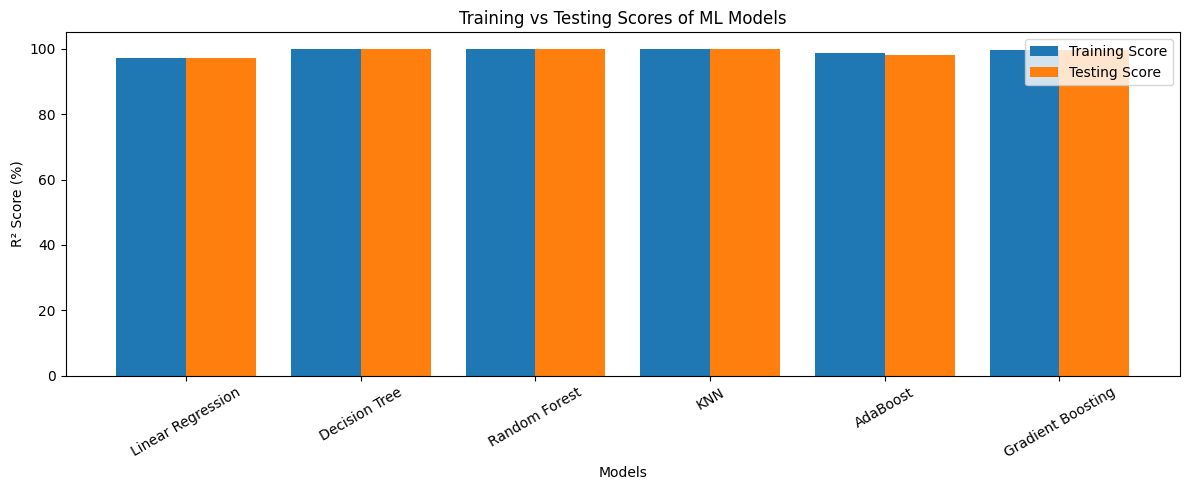

In [62]:
x = score['Model']
y = score['TrainingScores']
z = score['TestingScore']
width = 0.4
x_indices = np.arange(len(x))
plt.figure(figsize=(12, 5))
plt.bar(x_indices - width/2, y, width, label='Training Score')
plt.bar(x_indices + width/2, z, width, label='Testing Score')
plt.xticks(x_indices, x, rotation=30)
plt.xlabel('Models')
plt.ylabel('R² Score (%)')
plt.title('Training vs Testing Scores of ML Models')
plt.legend()
plt.tight_layout()
plt.show()

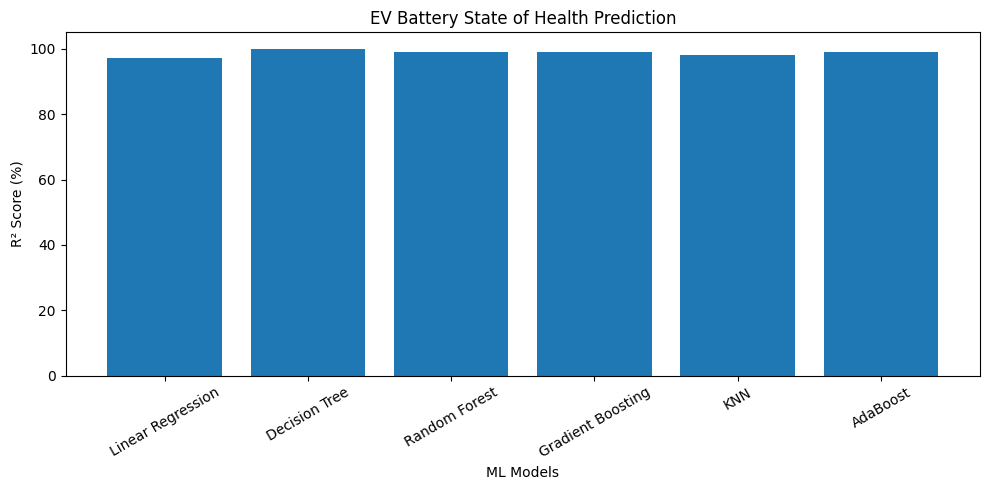

In [57]:
models = [
    'Linear Regression',
    'Decision Tree',
    'Random Forest',
    'Gradient Boosting',
    'KNN',
    'AdaBoost'
]
scores = [97, 100, 99, 99, 98, 99]
plt.figure(figsize=(10, 5))
plt.bar(models, scores)
plt.title('EV Battery State of Health Prediction')
plt.xlabel('ML Models')
plt.ylabel('R² Score (%)')
plt.ylim(0, 105)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

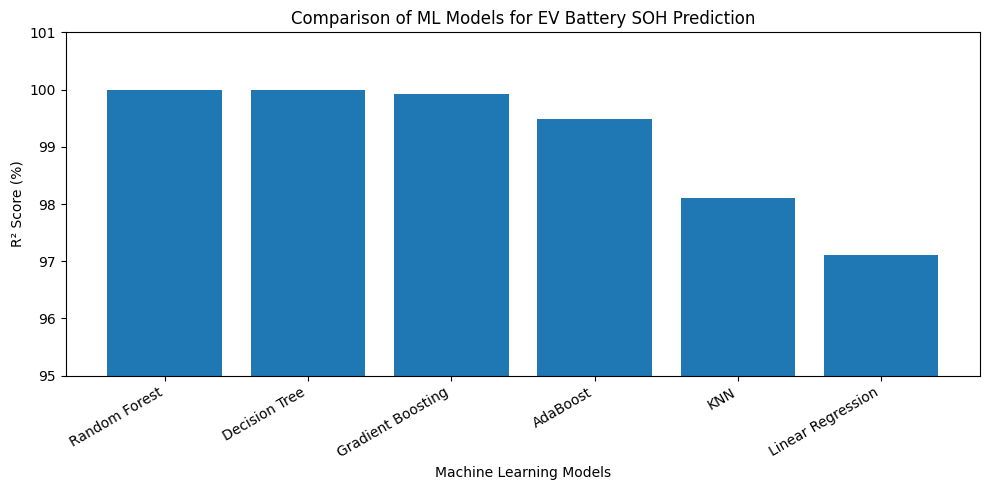

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(results['Model'], results['R2 Score (%)'])
plt.title('Comparison of ML Models for EV Battery SOH Prediction')
plt.xlabel('Machine Learning Models')
plt.ylabel('R² Score (%)')
plt.ylim(95, 101)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

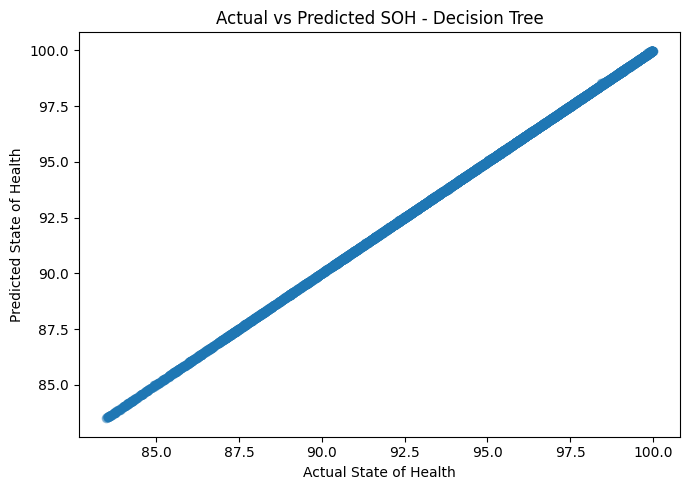

In [64]:
plt.figure(figsize=(7, 5))
plt.scatter(ytest, ypred_dt, alpha=0.4)
plt.xlabel("Actual State of Health")
plt.ylabel("Predicted State of Health")
plt.title("Actual vs Predicted SOH - Decision Tree")
plt.tight_layout()
plt.show()

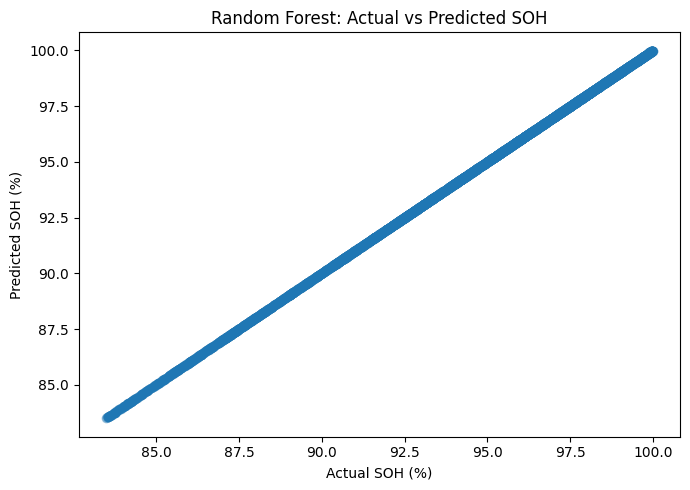

In [65]:
plt.figure(figsize=(7, 5))
plt.scatter(ytest, ypred_rf, alpha=0.4)
lo = min(ytest.min(), ypred_rf.min())
hi = max(ytest.max(), ypred_rf.max())
plt.plot([lo, hi], [lo, hi], '--')
plt.xlabel("Actual SOH (%)")
plt.ylabel("Predicted SOH (%)")
plt.title("Random Forest: Actual vs Predicted SOH")
plt.tight_layout()
plt.show()

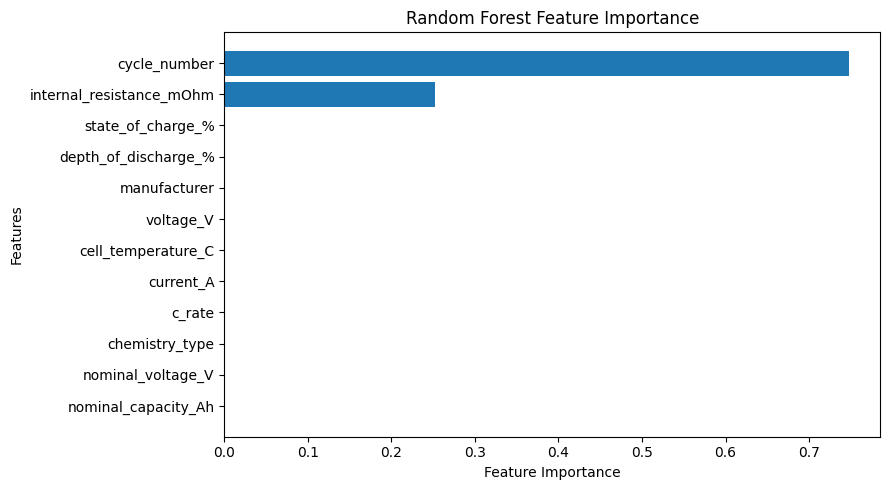

In [66]:
plt.figure(figsize=(9, 5))
plt.barh(
    importance['Feature'],
    importance['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Random Forest Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

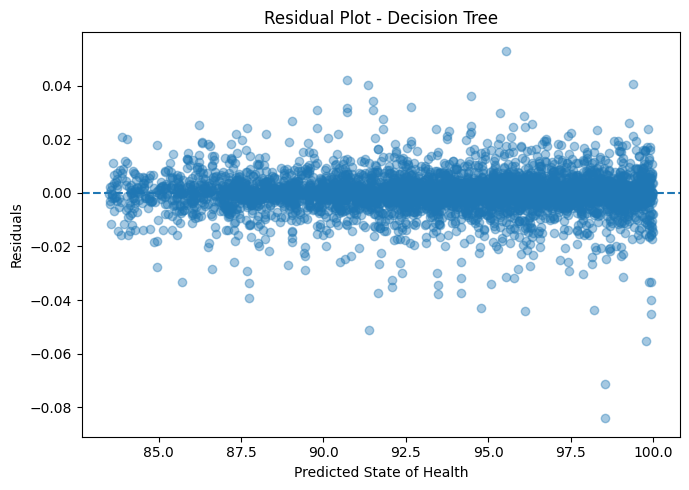

In [67]:
residuals = ytest - ypred_dt
plt.figure(figsize=(7, 5))
plt.scatter(ypred_dt, residuals, alpha=0.4)
plt.axhline(y=0, linestyle='--')
plt.xlabel("Predicted State of Health")
plt.ylabel("Residuals")
plt.title("Residual Plot - Decision Tree")
plt.tight_layout()
plt.show()

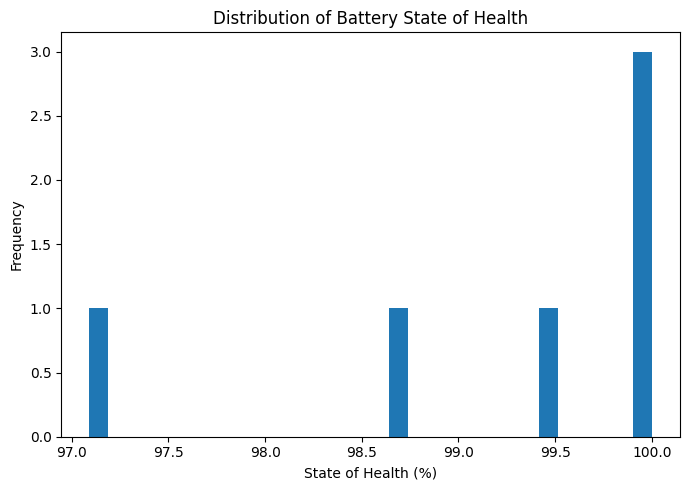

In [68]:
plt.figure(figsize=(7, 5))
plt.hist(y, bins=30)
plt.xlabel("State of Health (%)")
plt.ylabel("Frequency")
plt.title("Distribution of Battery State of Health")
plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(rf_model, 'ev_battery_soh_model.pkl')
joblib.dump(scaler, 'ev_battery_soh_scaler.pkl')

print("Model and scaler saved successfully!")